# Part 3: Advanced NLP Tasks

**NLTK VADER sentiment analysis** on the White House swimming pool post, followed by **spaCy entity, topic, and grammar analysis** of the Chiricahua National Park post.

*Note:* Entity extraction and noun phrases are used for **manual topic identification**, not statistical topic modeling such as LDA. Claims in the posts are analyzed as text, not fact-checked.

## 1. Setup
Install packages and download the required models. Run this cell once.

In [1]:
import nltk
import spacy
from IPython.display import display, HTML
from spacy import displacy

nltk.download("vader_lexicon", quiet=True)
nlp = spacy.load("en_core_web_sm")

## 2. Sentiment analysis with NLTK
VADER gives **neg**, **neu**, and **pos** proportions and a **compound** score from -1 to +1. The compound score is **not a percentage**.

In [2]:
from nltk.sentiment import SentimentIntensityAnalyzer

sent_text = "There is a Fake News report out there that I am going to remove the White House Press Room and bring back the old Swimming Pool, which lies directly underneath. Although I may move the Fake News to a less obnoxious location, the old swimming pool will never be brought back. I NEVER even thought to do such a stupid thing! Thank you for your attention to this matter. President DJT"

sia = SentimentIntensityAnalyzer()
scores = sia.polarity_scores(sent_text)
print(scores)
print("Overall:", "Positive" if scores["compound"] >= 0.05 else "Negative" if scores["compound"] <= -0.05 else "Neutral")

{'neg': 0.2, 'neu': 0.753, 'pos': 0.047, 'compound': -0.9148}
Overall: Negative


**Notes (update after running):**
- My earlier run showed a compound score of about **-0.91**, suggesting a strongly negative tone. Verify the actual output above.
- Words such as **obnoxious** and **stupid** contribute negative language. **NEVER** can affect negation/emphasis.
- The tone can be negative even when the subject itself is not inherently negative.
- Removing **thank** previously resulted in `pos: 0` in my test; this may depend on the exact text.

### Optional: visualize individual dictionary word scores
These are **lexicon scores**, not exact contributions to the final compound score.

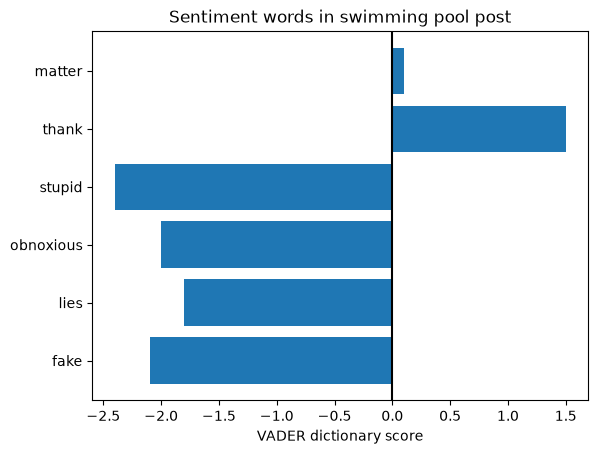

In [4]:
import re
import matplotlib.pyplot as plt

words = re.findall(r"\b[\w']+\b", sent_text.lower())
word_scores = {word: sia.lexicon.get(word, 0) for word in words}
word_scores = {word: score for word, score in word_scores.items() if score != 0}
plt.barh(list(word_scores), list(word_scores.values()))
plt.axvline(0, color="black")
plt.xlabel("VADER dictionary score")
plt.title("Sentiment words in swimming pool post")
plt.show()

## 3. spaCy: national parks announcement
This is a **different text** from the sentiment-analysis example.

In [5]:
topic_text = """I am proud to announce the NEWEST FLAGSHIP NATIONAL PARK in the Country, CHIRICAHUA NATIONAL PARK in ARIZONA! In my First Term, I signed the GREAT American Outdoors Act, one of the LARGEST Investments in National Parks in HISTORY, and designated a new National Park in the Great State of West Virginia, meaning, I’ve now given ALL Americans their 63rd and 64th National Park. No other President was able to get this done for America, and Arizona, a State I love and won BIG! Congratulations to GREAT Republican Congressman and America First Patriot Juan Ciscomani for his MAJOR WIN passing this Bill through Congress. Congratulations to all of our other Great Congressmen in the State, including Andy Biggs, David Schweikert, Eli Crane, Abe Hamadeh, and Paul Gosar. We are MAKING OUR PARKS, AND ARIZONA, GREAT AGAIN! President DONALD J. TRUMP"""

doc = nlp(topic_text)
print("Sentences:", len(list(doc.sents)))

Sentences: 7


### Named entities
**Named entities** are names of people, places, organizations, dates, and other recognized categories. The small English model may misclassify some capitalized phrases.

In [6]:
for ent in doc.ents:
    print(f"{ent.text:<40} {ent.label_:<10} {spacy.explain(ent.label_)}")

ARIZONA                                  GPE        Countries, cities, states
the GREAT American Outdoors Act          ORG        Companies, agencies, institutions, etc.
one                                      CARDINAL   Numerals that do not fall under another type
the LARGEST Investments                  ORG        Companies, agencies, institutions, etc.
National Park                            FAC        Buildings, airports, highways, bridges, etc.
the Great State of                       FAC        Buildings, airports, highways, bridges, etc.
West Virginia                            GPE        Countries, cities, states
Americans                                NORP       Nationalities or religious or political groups
63rd                                     ORDINAL    "first", "second", etc.
64th                                     ORDINAL    "first", "second", etc.
National Park                            FAC        Buildings, airports, highways, bridges, etc.
America              

### Visualize named entities

In [7]:
displacy.render(doc, style="ent", jupyter=True)

### Noun phrases
**Noun phrases** are groups of words centered on a noun, such as “the Great State of West Virginia.” They can suggest topics.

In [8]:
for chunk in doc.noun_chunks:
    print(chunk.text)

I
the NEWEST FLAGSHIP NATIONAL PARK
the Country
CHIRICAHUA NATIONAL PARK
ARIZONA
my First Term
I
the GREAT American Outdoors Act
the LARGEST Investments
National Parks
HISTORY
a new National Park
the Great State
West Virginia
I
ALL Americans
their 63rd and 64th National Park
No other President
this
America
Arizona
a State
I
BIG
Congratulations
GREAT Republican Congressman and America First Patriot Juan Ciscomani
his MAJOR WIN
this Bill
Congress
Congratulations
all
our other Great Congressmen
the State
Andy Biggs
David Schweikert
Eli Crane
Abe Hamadeh
Paul Gosar
We
OUR PARKS
ARIZONA
President DONALD J. TRUMP


### Topics / themes (manual interpretation)
1. **National parks and conservation:** Chiricahua National Park, national parks, American Outdoors Act.
2. **Geography:** Arizona and West Virginia.
3. **Politics and legislation:** Congress, the bill, and named members of Congress.
4. **Political self-promotion:** repeated references to achievements, congratulations, and “GREAT AGAIN.”

These are **human-inferred themes** supported by entities and noun phrases; spaCy is not automatically fitting a topic model here.

## 4. Advanced linguistic analysis
**POS** (part of speech) identifies grammatical categories. **Dependency parsing** identifies grammatical relationships, such as subject, object, and modifier.

In [9]:
import pandas as pd

rows = [(token.text, token.pos_, token.dep_, token.head.text) for token in list(doc.sents)[0]]
display(pd.DataFrame(rows, columns=["Word", "POS", "Dependency", "Head word"]))

,Word,POS,Dependency,Head word
0,I,PRON,nsubj,am
1,am,AUX,ROOT,am
2,proud,ADJ,acomp,am
3,to,PART,aux,announce
4,announce,VERB,xcomp,proud
5,the,DET,det,PARK
6,NEWEST,PROPN,compound,PARK
7,FLAGSHIP,PROPN,compound,NATIONAL
8,NATIONAL,PROPN,compound,PARK
9,PARK,PROPN,dobj,announce


### Dependency visualization
Use the first sentence so the diagram stays readable. Arrows show how words depend on other words.

In [10]:
first_sentence = list(doc.sents)[0]
displacy.render(first_sentence, style="dep", jupyter=True, options={"compact": True, "distance": 90})

### Optional: inspect other sentences

In [11]:
for i, sentence in enumerate(doc.sents):
    print(i, sentence.text[:110])

# Change 0 to another sentence index to visualize it.
sentence_number = 0
displacy.render(list(doc.sents)[sentence_number], style="dep", jupyter=True, options={"compact": True, "distance": 90})

0 I am proud to announce the NEWEST FLAGSHIP NATIONAL PARK in the Country, CHIRICAHUA NATIONAL PARK in ARIZONA!
1 In my First Term, I signed the GREAT American Outdoors Act, one of the LARGEST Investments in National Parks i
2 No other President was able to get this done for America, and Arizona, a State I love and won BIG!
3 Congratulations to GREAT Republican Congressman and America First Patriot Juan Ciscomani for his MAJOR WIN pas
4 Congratulations to all of our other Great Congressmen in the State, including Andy Biggs, David Schweikert, El
5 We are MAKING OUR PARKS, AND ARIZONA, GREAT AGAIN!
6 President DONALD J. TRUMP


## 5. Brief conclusion
- **NLTK VADER:** The swimming pool post uses strongly negative wording, despite discussing a relatively ordinary subject.
- **spaCy entities:** The parks post includes locations, politicians, and legislation, helping reveal its main subjects.
- **Noun phrases:** Support the themes of parks, geography, politics, and claimed achievements.
- **Dependency parsing:** Shows how words relate grammatically within a sentence.

**Limitations:** VADER can miss sarcasm and context. spaCy can misidentify entities, especially in all-caps political posts. Extracting themes manually is not the same as fitting a statistical topic model.